In [1]:
!pip -q install kagglehub requests
import cv2, os, time, pickle, glob, shutil, random, requests
import concurrent.futures as cf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("OpenCV:", cv2.__version__)
sift = cv2.SIFT_create(nfeatures=2000)

OpenCV: 5.0.0


In [2]:
N_DB, N_TEST, N_LANDMARKS = 8, 3, 5
NEED = N_DB + N_TEST
HEADERS = {"User-Agent": "ColabLandmarkLab/1.0 (student computer vision project)"}

# ---------- Option A: Google-Landmarks from Kaggle ----------
def fetch_img(url):
    try:
        r = requests.get(url, timeout=8)
        if r.status_code != 200: return None
        img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
        if img is None or min(img.shape[:2]) < 200: return None
        return img
    except Exception:
        return None

def from_google():
    import kagglehub
    path = kagglehub.dataset_download("google/google-landmarks-dataset")
    csvs = glob.glob(path + "/**/*.csv", recursive=True)
    assert csvs, "No CSV found"
    csv_file = next((c for c in csvs if "train" in os.path.basename(c).lower()), csvs[0])
    df = pd.read_csv(csv_file, nrows=600000)
    print("Using:", os.path.basename(csv_file), "| columns:", list(df.columns))
    url_col = next(c for c in df.columns if "url" in c.lower())
    id_col = next(c for c in df.columns if "landmark" in c.lower() or c.lower() in ("label", "class"))
    df = df[[url_col, id_col]].dropna()
    classes = {}
    for lid in df[id_col].value_counts().index[:60]:
        if len(classes) >= N_LANDMARKS + 1: break
        sub = df[df[id_col] == lid]
        urls = sub[url_col].sample(min(60, len(sub)), random_state=1).tolist()
        with cf.ThreadPoolExecutor(16) as ex:
            imgs = [i for i in ex.map(fetch_img, urls) if i is not None]
        print(f"landmark_id {lid}: {len(imgs)}/{len(urls)} downloaded")
        if len(imgs) >= NEED:
            classes[f"landmark_{lid}"] = imgs
    assert len(classes) >= N_LANDMARKS, "Too few working URLs"
    names = list(classes.keys())
    unknown = classes[names[N_LANDMARKS]][:2] if len(names) > N_LANDMARKS else []
    return {k: classes[k] for k in names[:N_LANDMARKS]}, unknown

# ---------- Option B: Wikimedia Commons (fallback) ----------
API = "https://commons.wikimedia.org/w/api.php"
WIKI_LANDMARKS = {
    "Eiffel_Tower":      "Eiffel Tower Paris",
    "Taj_Mahal":         "Taj Mahal Agra",
    "Colosseum":         "Colosseum Rome",
    "Statue_of_Liberty": "Statue of Liberty New York",
    "Great_Wall":        "Great Wall of China",
}

def fetch_urls(query):
    params = dict(action="query", generator="search", gsrsearch=query, gsrnamespace=6,
                  gsrlimit=50, prop="imageinfo", iiprop="url|mime", iiurlwidth=800, format="json")
    r = requests.get(API, params=params, headers=HEADERS, timeout=30).json()
    urls = []
    for p in r.get("query", {}).get("pages", {}).values():
        ii = p.get("imageinfo", [{}])[0]
        if ii.get("mime") == "image/jpeg":
            urls.append(ii.get("thumburl") or ii.get("url"))
    random.seed(1); random.shuffle(urls)
    return urls

def wiki_images(query, n):
    imgs = []
    for u in fetch_urls(query):
        if len(imgs) >= n: break
        try:
            r = requests.get(u, headers=HEADERS, timeout=30)
            if r.status_code == 200 and len(r.content) > 5000:
                im = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
                if im is not None: imgs.append(im)
            else:
                time.sleep(3)
        except Exception:
            time.sleep(2)
        time.sleep(1.0)
    return imgs

def from_wiki():
    classes = {}
    for name, q in WIKI_LANDMARKS.items():
        classes[name] = wiki_images(q, NEED)
        print(f"{name:20s} downloaded {len(classes[name])}")
    unknown = wiki_images("Pyramid of Giza", 2)
    print("unknown (pyramid) images:", len(unknown))
    return classes, unknown

# ---------- Run: try Kaggle first, fall back to Wikimedia ----------
USE_KAGGLE_FIRST = True
classes = unknown = None
if USE_KAGGLE_FIRST:
    try:
        classes, unknown = from_google()
        print("Dataset source: Google-Landmarks (Kaggle)")
    except Exception as e:
        print("Kaggle route failed:", repr(e)[:200], "\nFalling back to Wikimedia...")
if classes is None:
    classes, unknown = from_wiki()
    print("Dataset source: Wikimedia Commons")

# ---------- Write folders ----------
for d in ["/content/landmarks", "/content/test_queries", "/content/unknown"]:
    shutil.rmtree(d, ignore_errors=True)
for name, imgs in classes.items():
    n_test = min(N_TEST, max(1, len(imgs) // 4))
    for sub, items in [("test_queries", imgs[:n_test]), ("landmarks", imgs[n_test:n_test + N_DB])]:
        os.makedirs(f"/content/{sub}/{name}", exist_ok=True)
        for i, im in enumerate(items):
            cv2.imwrite(f"/content/{sub}/{name}/img{i+1}.jpg", im)
os.makedirs("/content/unknown", exist_ok=True)
for i, im in enumerate(unknown):
    cv2.imwrite(f"/content/unknown/img{i+1}.jpg", im)

DB_PATH = "/content/landmarks"
print("\nDatabase:", {l: len(os.listdir(f'{DB_PATH}/{l}')) for l in os.listdir(DB_PATH)})
print("Test queries:", {l: len(os.listdir(f'/content/test_queries/{l}')) for l in os.listdir('/content/test_queries')})
print("Unknown images:", len(os.listdir("/content/unknown")))

100%|██████████| 1.12k/1.12k [00:00<00:00, 1.18MB/s]

Extracting files...
Using: train.csv | columns: ['id', 'url', 'landmark_id']
Kaggle route failed: AssertionError('Too few working URLs') 
Falling back to Wikimedia...


Eiffel_Tower         downloaded 11
Taj_Mahal            downloaded 11
Colosseum            downloaded 11
Statue_of_Liberty    downloaded 11
Great_Wall           downloaded 11
unknown (pyramid) images: 2
Dataset source: Wikimedia Commons

Database: {'Statue_of_Liberty': 8, 'Taj_Mahal': 8, 'Eiffel_Tower': 8, 'Colosseum': 8, 'Great_Wall': 8}
Test queries: {'Statue_of_Liberty': 2, 'Taj_Mahal': 2, 'Eiffel_Tower': 2, 'Colosseum': 2, 'Great_Wall': 2}
Unknown images: 2


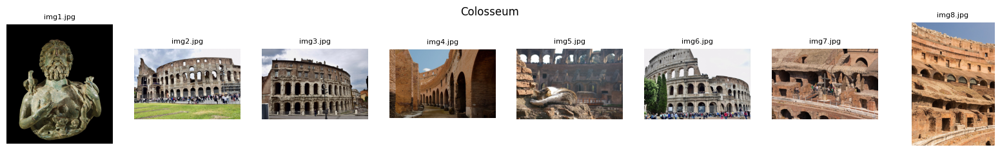

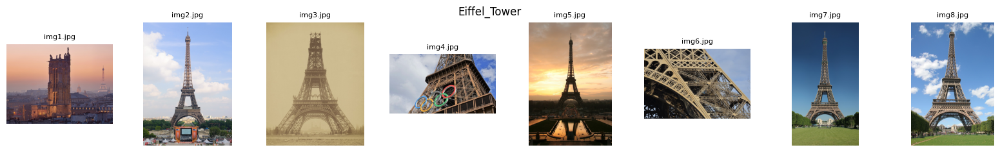

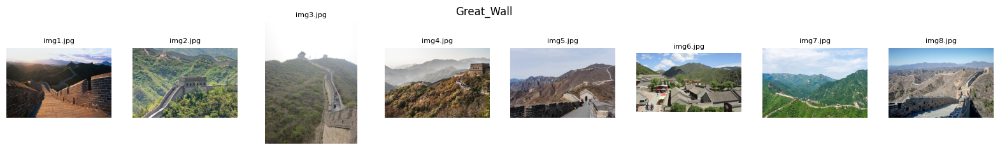

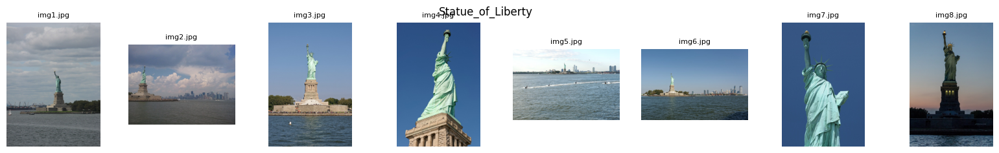

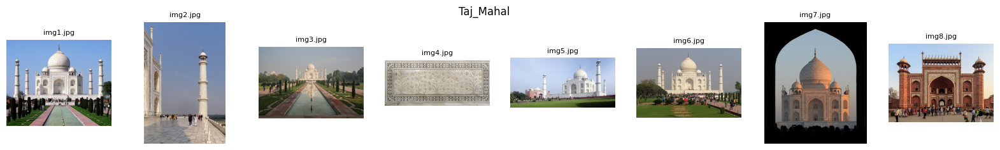

In [3]:
for lm in sorted(os.listdir(DB_PATH)):
    paths = sorted(glob.glob(f"{DB_PATH}/{lm}/*.jpg"))
    fig, axs = plt.subplots(1, len(paths), figsize=(2.5*len(paths), 2.5))
    for ax, p in zip(np.atleast_1d(axs), paths):
        ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.basename(p), fontsize=8); ax.axis("off")
    fig.suptitle(lm); plt.show()

Colosseum: 8 images, 16003 keypoints
Eiffel_Tower: 8 images, 13133 keypoints
Great_Wall: 8 images, 14358 keypoints
Statue_of_Liberty: 8 images, 8663 keypoints
Taj_Mahal: 8 images, 13175 keypoints
Saved sift_database.pkl


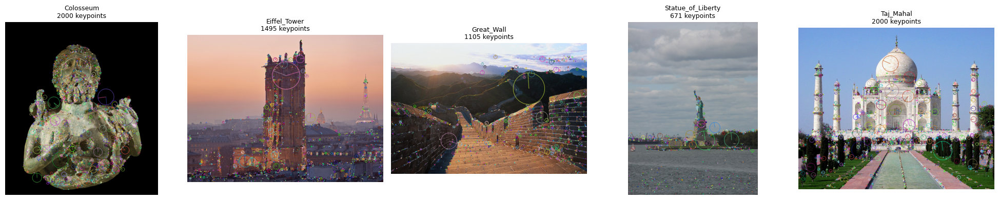

In [4]:
def load_resized(path, max_dim=800):
    img = cv2.imread(path)
    if img is None: return None
    h, w = img.shape[:2]
    s = max_dim / max(h, w)
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img

database = {}
for lm in sorted(os.listdir(DB_PATH)):
    folder = os.path.join(DB_PATH, lm)
    if not os.path.isdir(folder): continue
    database[lm] = []
    for fn in sorted(os.listdir(folder)):
        img = load_resized(os.path.join(folder, fn))
        if img is None: continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        kp, des = sift.detectAndCompute(gray, None)
        if des is None: continue
        database[lm].append(dict(name=fn, img=img, kp=kp, des=des))
    print(f"{lm}: {len(database[lm])} images, {sum(len(d['kp']) for d in database[lm])} keypoints")

def kp_to_tuple(kps): return [(k.pt, k.size, k.angle, k.response, k.octave, k.class_id) for k in kps]
save = {lm: [dict(name=d['name'], kp=kp_to_tuple(d['kp']), des=d['des']) for d in v]
        for lm, v in database.items()}
pickle.dump(save, open("sift_database.pkl", "wb"))
print("Saved sift_database.pkl")

fig, axs = plt.subplots(1, len(database), figsize=(4*len(database), 4))
for ax, (lm, items) in zip(np.atleast_1d(axs), database.items()):
    d = items[0]
    vis = cv2.drawKeypoints(d['img'], d['kp'], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{lm}\n{len(d['kp'])} keypoints", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

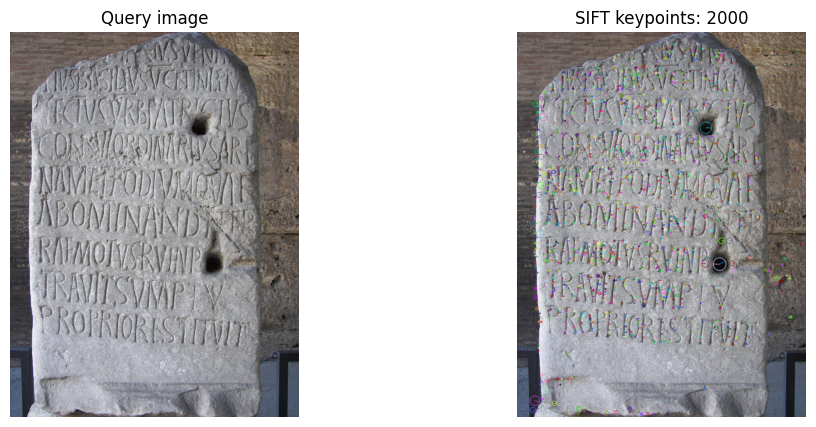

In [5]:
def process_query(img_bgr, show=True):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    if show:
        vis = cv2.drawKeypoints(img_bgr, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        ax[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("Query image")
        ax[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"SIFT keypoints: {len(kp)}")
        for a in ax: a.axis("off")
        plt.show()
    return gray, kp, des

first = sorted(os.listdir("/content/test_queries"))[0]
QUERY_PATH = f"/content/test_queries/{first}/img1.jpg"
query_img = load_resized(QUERY_PATH)
_ = process_query(query_img)

In [6]:
RATIO       = 0.75   # Lowe's ratio
MIN_GOOD    = 15     # min reliable matches to attempt homography
MIN_INLIERS = 12     # min RANSAC inliers to accept
MARGIN      = 1.3    # best must beat runner-up by this factor
RANSAC_THR  = 5.0

bf = cv2.BFMatcher(cv2.NORM_L2)   # Brute-Force, Euclidean distance

def ratio_matches(des_ref, des_q):
    if des_ref is None or des_q is None or len(des_ref) < 2 or len(des_q) < 2:
        return []
    knn = bf.knnMatch(des_ref, des_q, k=2)   # k = 2
    return [m for m, n in (p for p in knn if len(p) == 2) if m.distance < RATIO * n.distance]

def verify_homography(ref_d, kp_q, good, q_shape):
    if len(good) < MIN_GOOD: return None
    src = np.float32([ref_d['kp'][m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst = np.float32([kp_q[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THR)
    if H is None: return None
    inliers = int(mask.sum())
    h, w = ref_d['img'].shape[:2]
    corners = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    proj = cv2.perspectiveTransform(corners, H)
    area = cv2.contourArea(proj)
    qa = q_shape[0] * q_shape[1]
    if not cv2.isContourConvex(proj.astype(np.int32)) or not (0.01*qa < area < 2.0*qa):
        return None
    return H, mask.ravel(), inliers, proj

def recognize(query_img, verbose=True):
    t0 = time.time()
    gray, kp_q, des_q = process_query(query_img, show=False)
    results = {}
    for lm, items in database.items():
        best = dict(good=0, inliers=0, ref=None, goodlist=[], ver=None)
        for d in items:
            good = ratio_matches(d['des'], des_q)
            ver = verify_homography(d, kp_q, good, query_img.shape)
            inl = ver[2] if ver else 0
            if (inl, len(good)) > (best['inliers'], best['good']):
                best = dict(good=len(good), inliers=inl, ref=d, goodlist=good, ver=ver)
        results[lm] = best

    ranking = sorted(results.items(), key=lambda x: (x[1]['inliers'], x[1]['good']), reverse=True)
    top, top_r = ranking[0]
    second_inl = ranking[1][1]['inliers'] if len(ranking) > 1 else 0
    recognized = (top_r['ver'] is not None and top_r['inliers'] >= MIN_INLIERS
                  and top_r['inliers'] >= MARGIN * max(second_inl, 1))
    elapsed = time.time() - t0

    if verbose:
        print("Ranking:")
        for lm, r in ranking:
            print(f"  {lm:22s} good={r['good']:4d}  inliers={r['inliers']:4d}")
    return dict(pred=top if recognized else "Unknown / Rejected", best_guess=top,
                recognized=recognized, n_kp=len(kp_q), good=top_r['good'],
                inliers=top_r['inliers'], time=elapsed, res=top_r, kp_q=kp_q, ranking=ranking)

Ranking:
  Great_Wall             good=  21  inliers=   0
  Colosseum              good=  20  inliers=   0
  Taj_Mahal              good=  19  inliers=   0
  Eiffel_Tower           good=  14  inliers=   0
  Statue_of_Liberty      good=  11  inliers=   0
❌ REJECTED (best guess 'Great_Wall' but evidence insufficient)
Keypoints in query : 2000
Reliable matches   : 21
RANSAC inliers     : 0
Processing time    : 5.958 s


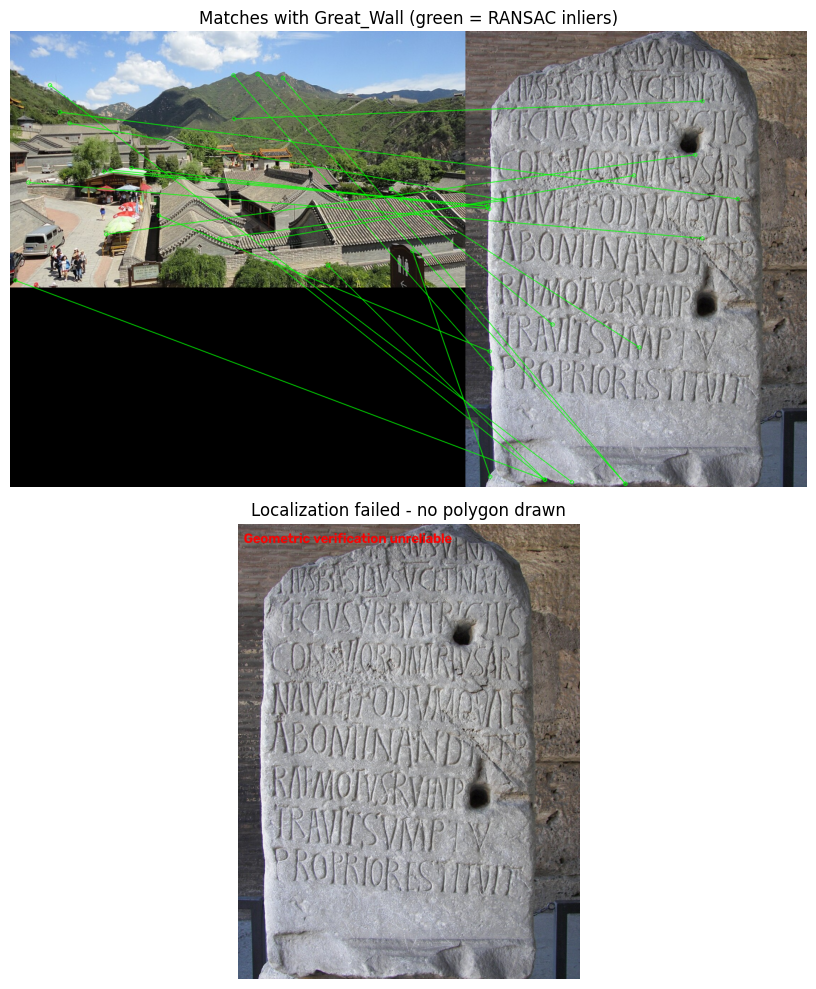

In [7]:
def show_result(query_img, out):
    r = out['res']
    print("="*50)
    if out['recognized']: print(f"✅ RECOGNIZED: {out['pred']}")
    else: print(f"❌ REJECTED (best guess '{out['best_guess']}' but evidence insufficient)")
    print(f"Keypoints in query : {out['n_kp']}")
    print(f"Reliable matches   : {out['good']}")
    print(f"RANSAC inliers     : {out['inliers']}")
    print(f"Processing time    : {out['time']:.3f} s")
    print("="*50)
    if r['ref'] is None or not r['goodlist']:
        print("No matches to display."); return

    mask = r['ver'][1].tolist() if r['ver'] else None
    match_vis = cv2.drawMatches(r['ref']['img'], r['ref']['kp'], query_img, out['kp_q'],
                                r['goodlist'], None, matchesMask=mask, matchColor=(0,255,0),
                                singlePointColor=None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    loc = query_img.copy()
    if out['recognized'] and r['ver']:
        cv2.polylines(loc, [np.int32(r['ver'][3])], True, (0,0,255), 4)
        cv2.putText(loc, f"{out['pred']} ({out['inliers']} inliers)", (10, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0,0,255), 2)
        loc_title = "Localized landmark"
    else:
        cv2.putText(loc, "Geometric verification unreliable", (10, 35),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0,0,255), 2)
        loc_title = "Localization failed - no polygon drawn"

    fig, ax = plt.subplots(2, 1, figsize=(14, 10))
    ax[0].imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
    ax[0].set_title(f"Matches with {out['best_guess']} (green = RANSAC inliers)")
    ax[1].imshow(cv2.cvtColor(loc, cv2.COLOR_BGR2RGB)); ax[1].set_title(loc_title)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

out = recognize(query_img)
show_result(query_img, out)


########## Original ##########
❌ REJECTED (best guess 'Great_Wall' but evidence insufficient)
Keypoints in query : 2000
Reliable matches   : 21
RANSAC inliers     : 0
Processing time    : 4.831 s


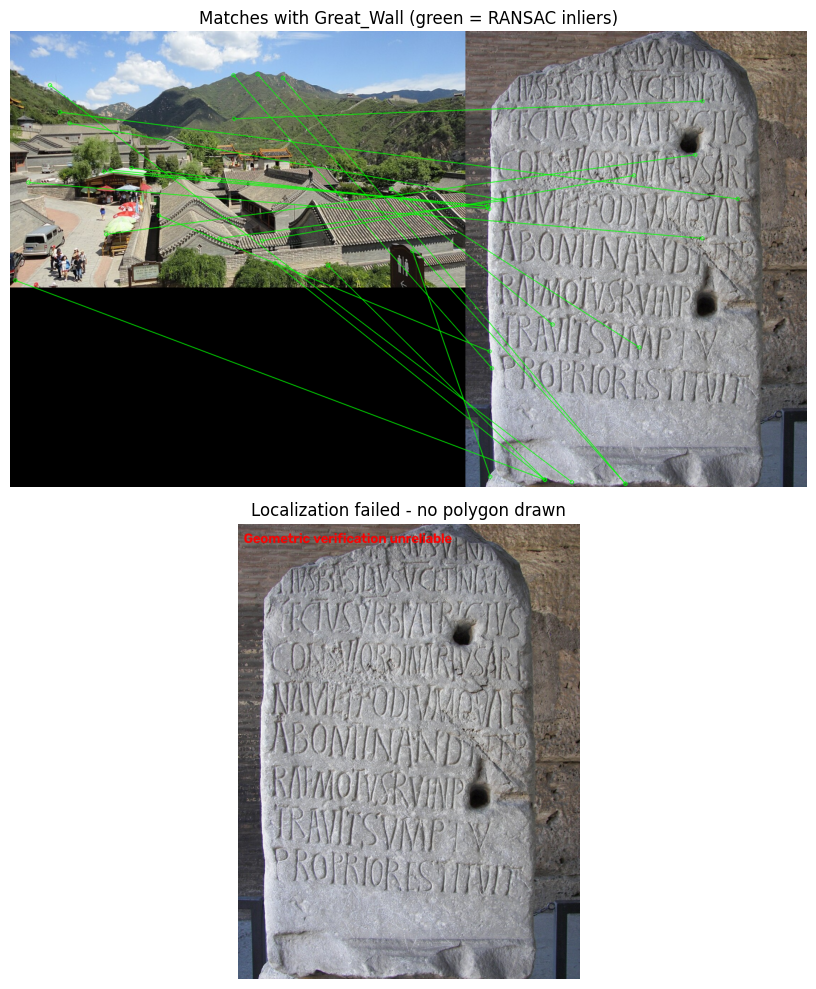


########## Rotated (45°) ##########
❌ REJECTED (best guess 'Taj_Mahal' but evidence insufficient)
Keypoints in query : 2000
Reliable matches   : 22
RANSAC inliers     : 0
Processing time    : 5.344 s


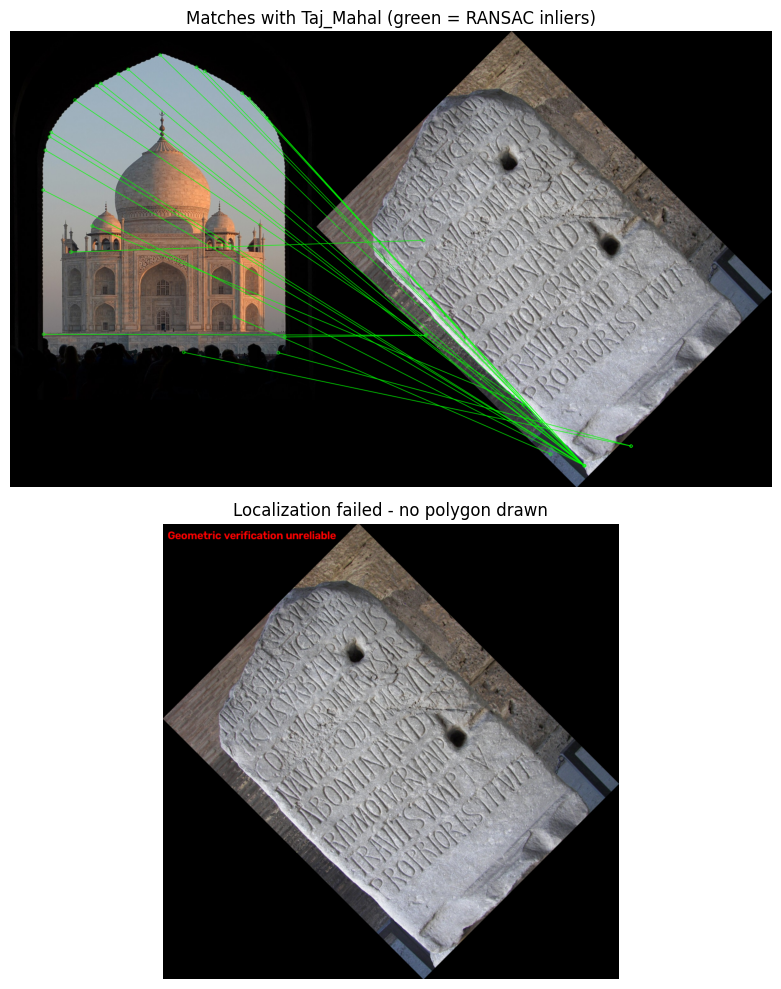


########## Resized (50%) ##########
❌ REJECTED (best guess 'Taj_Mahal' but evidence insufficient)
Keypoints in query : 1007
Reliable matches   : 82
RANSAC inliers     : 0
Processing time    : 3.536 s


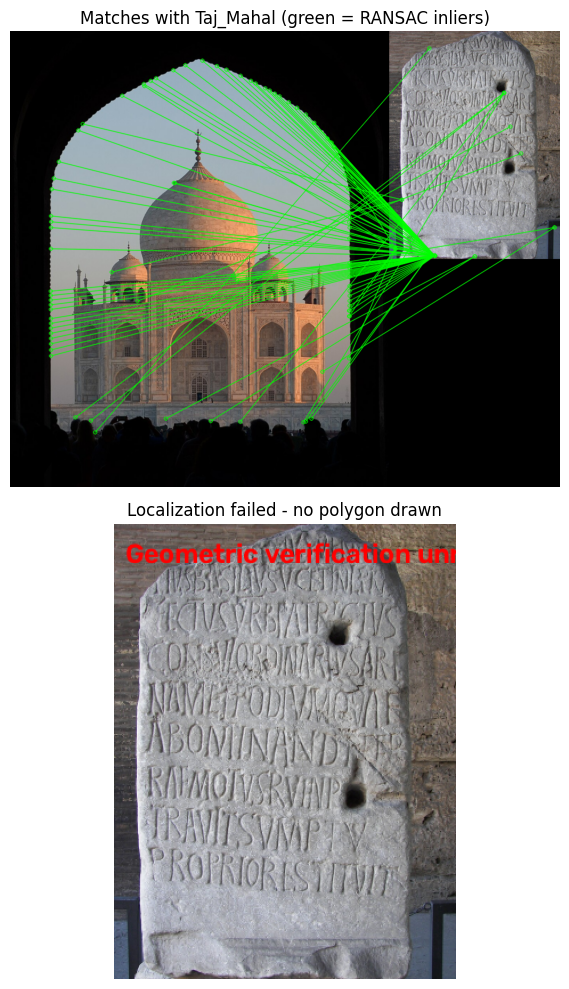


########## Low brightness ##########
❌ REJECTED (best guess 'Great_Wall' but evidence insufficient)
Keypoints in query : 1205
Reliable matches   : 21
RANSAC inliers     : 0
Processing time    : 3.043 s


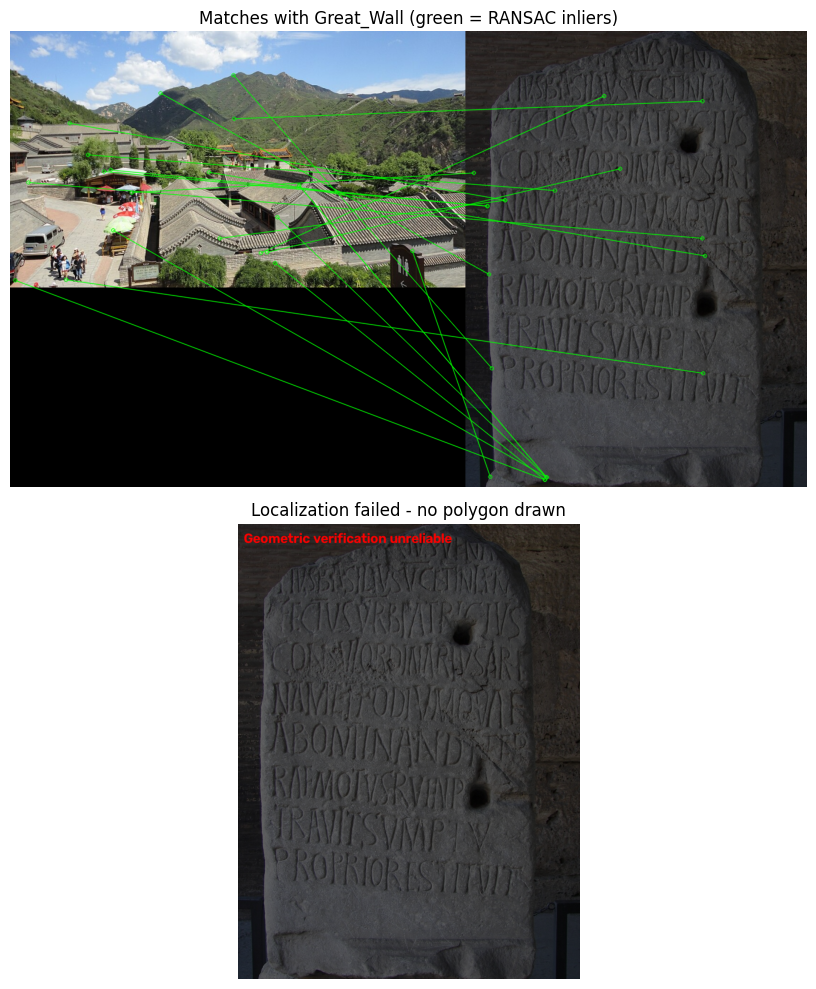


########## Different viewpoint ##########
❌ REJECTED (best guess 'Colosseum' but evidence insufficient)
Keypoints in query : 2000
Reliable matches   : 21
RANSAC inliers     : 0
Processing time    : 5.223 s


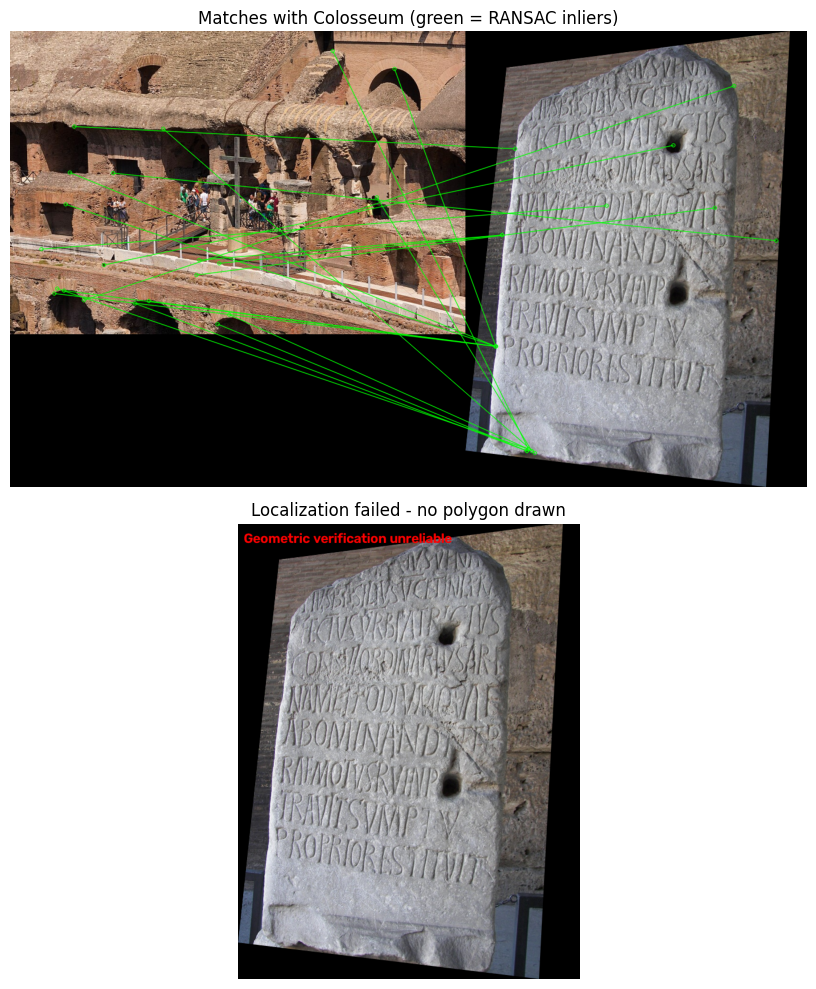


########## Unknown landmark ##########
❌ REJECTED (best guess 'Taj_Mahal' but evidence insufficient)
Keypoints in query : 2000
Reliable matches   : 84
RANSAC inliers     : 0
Processing time    : 6.341 s


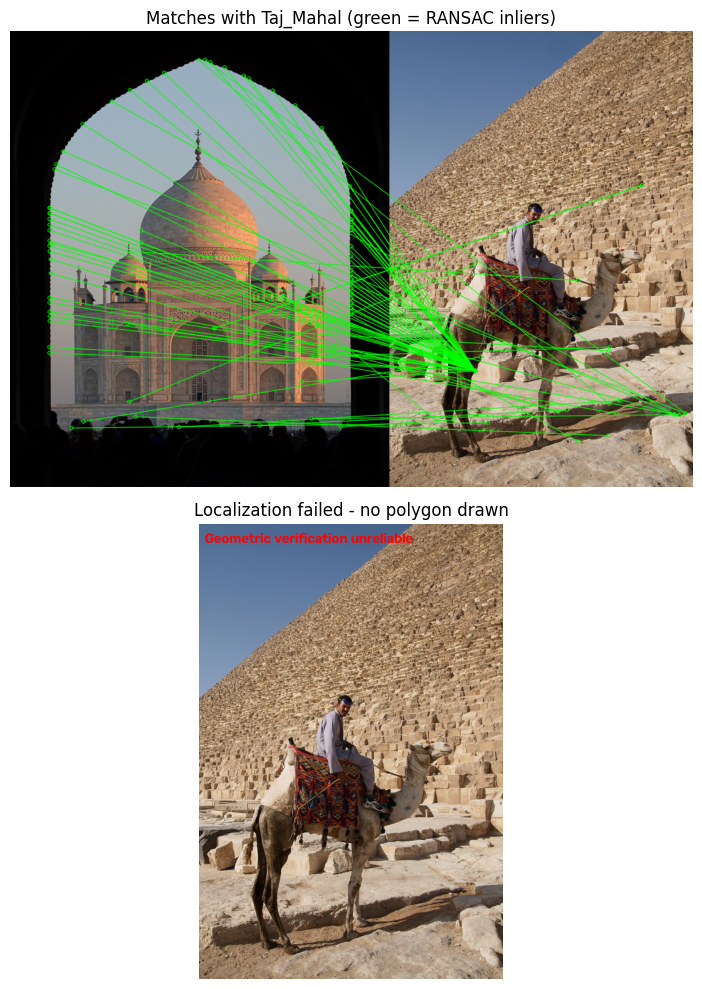

,Test,Predicted,Keypoints,Reliable matches,RANSAC inliers,Decision,Time (s)
0,Original,Unknown / Rejected,2000,21,0,Rejected,4.831
1,Rotated (45°),Unknown / Rejected,2000,22,0,Rejected,5.344
2,Resized (50%),Unknown / Rejected,1007,82,0,Rejected,3.536
3,Low brightness,Unknown / Rejected,1205,21,0,Rejected,3.043
4,Different viewpoint,Unknown / Rejected,2000,21,0,Rejected,5.223
5,Unknown landmark,Unknown / Rejected,2000,84,0,Rejected,6.341


In [8]:
BASE    = f"/content/test_queries/{first}/img1.jpg"
UNKNOWN = "/content/unknown/img1.jpg"
assert os.path.exists(UNKNOWN), "No unknown image found. Upload one to /content/unknown/img1.jpg"

def rotate(img, angle=45):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    cos, sin = abs(M[0,0]), abs(M[0,1])
    nw, nh = int(h*sin + w*cos), int(h*cos + w*sin)
    M[0,2] += nw/2 - w/2; M[1,2] += nh/2 - h/2
    return cv2.warpAffine(img, M, (nw, nh))

def resize(img, f=0.5): return cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
def darken(img, f=0.4): return np.clip(img.astype(np.float32)*f, 0, 255).astype(np.uint8)
def viewpoint(img):
    h, w = img.shape[:2]
    src = np.float32([[0,0],[w,0],[w,h],[0,h]])
    dst = np.float32([[0.12*w,0.08*h],[0.95*w,0],[0.88*w,h],[0,0.92*h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))

base = load_resized(BASE)
tests = {
    "Original":            base,
    "Rotated (45°)":       rotate(base, 45),
    "Resized (50%)":       resize(base, 0.5),
    "Low brightness":      darken(base, 0.4),
    "Different viewpoint": viewpoint(base),
    "Unknown landmark":    load_resized(UNKNOWN),
}

rows = []
for name, img in tests.items():
    print(f"\n########## {name} ##########")
    o = recognize(img, verbose=False)
    show_result(img, o)
    rows.append({"Test": name, "Predicted": o['pred'], "Keypoints": o['n_kp'],
                 "Reliable matches": o['good'], "RANSAC inliers": o['inliers'],
                 "Decision": "Recognized" if o['recognized'] else "Rejected",
                 "Time (s)": round(o['time'], 3)})

df_res = pd.DataFrame(rows)
display(df_res)
df_res.to_csv("results.csv", index=False)

In [9]:
TEST_DIR = "/content/test_queries"
correct = total = 0
for lm in sorted(os.listdir(TEST_DIR)):
    for fn in sorted(os.listdir(os.path.join(TEST_DIR, lm))):
        img = load_resized(os.path.join(TEST_DIR, lm, fn))
        o = recognize(img, verbose=False)
        total += 1; correct += (o['pred'] == lm)
        print(f"{lm}/{fn}: predicted={o['pred']}  inliers={o['inliers']}")
print(f"\nAccuracy: {correct}/{total} = {100*correct/total:.1f}%")

Colosseum/img1.jpg: predicted=Unknown / Rejected  inliers=0
Colosseum/img2.jpg: predicted=Colosseum  inliers=21
Eiffel_Tower/img1.jpg: predicted=Unknown / Rejected  inliers=7
Eiffel_Tower/img2.jpg: predicted=Unknown / Rejected  inliers=0
Great_Wall/img1.jpg: predicted=Unknown / Rejected  inliers=0
Great_Wall/img2.jpg: predicted=Unknown / Rejected  inliers=0
Statue_of_Liberty/img1.jpg: predicted=Unknown / Rejected  inliers=0
Statue_of_Liberty/img2.jpg: predicted=Unknown / Rejected  inliers=0
Taj_Mahal/img1.jpg: predicted=Unknown / Rejected  inliers=0
Taj_Mahal/img2.jpg: predicted=Taj_Mahal  inliers=78

Accuracy: 2/10 = 20.0%
